In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("../..")

# clock/03 — order id (oid)

**Hypothesis.** For each instruction the LM assigns an *order id* in the sequence
of appearance. At `b = ` the LM just looks up the instruction with order id 2
(1-indexed) and implements it. The question: **is the order id disentangled from
the instruction content?**

**Causal setup (cross-prompt interchange).** Source prompt has conditions
(s1, s2, s3); destination has (d1, d2, d3). Capture the latent at the source's
`c = ` (order id 3, content s3) and patch it into the destination's `b = `
(order id 2, content d2). Patch a consecutive **5-layer window** centered at `l`,
sweep `l` over `range(0, n_layer, step)`, for three latent types:
residual (`layer_name_format`), mlp (`mlp_module_name_format`),
attn (`attn_module_name_format`).

**Expectation (first generated token).**
- *Late layers*: the patch just copies the source's prediction → first token of **s3**.
- *Early–middle layers* (if order id is disentangled): the patched run emits the
  first token of **d3** (the destination's *own* 3rd condition) — the order id
  transports, the content does not.

Start with the **first generated token**; consecutive generation is a follow-up.

In [2]:
import os
import json
import logging

import numpy as np
import torch
from rich.console import Console
from rich.theme import Theme

from src.utils import env_utils, logging_utils

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "4,5,6,7")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
logging_utils.configure(level=logging.INFO)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
MODEL_SHORT = MODEL_NAME.split("/")[-1]
VERSION = "conditions"
CACHE_ROOT = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "multistep_clock", VERSION, MODEL_SHORT)

from src.models import ModelandTokenizer
mt = ModelandTokenizer(
    model_key=MODEL_NAME, dtype=torch.bfloat16, device_map="auto", attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")
print(f"residual={mt.layer_name_format}  mlp={mt.mlp_module_name_format}  attn={mt.attn_module_name_format}")

2026-06-09 16:25:01 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-09 16:25:02 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-09 16:25:02 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-09 16:25:02 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-09 16:25:02 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-09 16:25:02 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-09 16:25:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-09 16:25:24 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-09 16:25:24 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40
residual=model.layers.{}  mlp=model.layers.{}.mlp  attn=model.layers.{}.self_attn


## 1. Build source / destination prefills

Source cut at `c = ` (order id 3), destination cut at `b = ` (order id 2). We also
cut the destination at `c = ` to read its *own* 3rd-condition first token (the
order-id-transported reference).

In [32]:
import re
from src.goals.multistep_label import LabeledGeneration


def load_labeled(sample_name, modularity="monolithic"):
    base = os.path.join(CACHE_ROOT, modularity, sample_name)
    with open(os.path.join(base, "labels.json")) as f:
        lab = LabeledGeneration.from_dict(json.load(f))
    with open(os.path.join(base, "completion.json")) as f:
        comp = json.load(f)
    return lab, comp


def cut_after_assignment(generation, var):
    m = re.search(rf"(?m)^\s*{re.escape(var)}\s*=", generation)
    if m is None:
        raise ValueError(f"no '{var} =' assignment line found")
    return m.end()


def build_prefill(sample_name, var, modularity="monolithic"):
    lab, comp = load_labeled(sample_name, modularity)
    cut = cut_after_assignment(lab.generation, var)
    return lab.full_prompt + lab.generation[:cut], lab


### ---- pick a source / destination pair (monolithic, ≥3 conditions) ----
SRC_SAMPLE = "cond_0053"     # provides the order-id-3 latent  (its `c =`)
DST_SAMPLE = "cond_0014"     # patched at its `b =` (order id 2)
### ----------------------------------------------------------------------
src_prefill, src_lab = build_prefill(SRC_SAMPLE, "c")     # s: order id 3
dst_prefill_b, dst_lab = build_prefill(DST_SAMPLE, "b")   # d: order id 2  (patch target)
dst_prefill_c, _ = build_prefill(DST_SAMPLE, "c")         # d: order id 3  (reference)

rich_print(f"[bold]SOURCE[/bold] {SRC_SAMPLE} — conditions:")
for i, sl in enumerate(src_lab.labels):
    rich_print(f"  s{i+1}: {sl.step_text}" + ("   ← captured @ `c =`" if i == 2 else ""))
rich_print(f"[bold]DEST[/bold]   {DST_SAMPLE} — conditions:")
for i, sl in enumerate(dst_lab.labels):
    tag = "   ← patched @ `b =`" if i == 1 else ("   ← order-id ref (d3)" if i == 2 else "")
    rich_print(f"  d{i+1}: {sl.step_text}{tag}")

SOURCE cond_0053 — conditions:

s1: n is odd

s2: n is less than or equal to 50

s3: n is a perfect square   ← captured @ `c =`

s4: the sum of n's digits is greater than 10

DEST   cond_0014 — conditions:

d1: n is divisible by 7

d2: n is positive   ← patched @ `b =`

d3: n is a prime number   ← order-id ref (d3)

In [42]:
from src.functional import generate_with_patch

test_prompt = dst_prefill_b
test_prompt = test_prompt.replace("b =", "c =")

test_gen = generate_with_patch(
    mt = mt,
    inputs = test_prompt,
    n_gen_per_prompt = 1,
    do_sample = True,
    max_new_tokens = 16,
    remove_prefix = True
)[0]

rich_print(f"[white]{test_prompt}[/white][sea_green1]{test_gen}[/sea_green1]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:

1. n is divisible by 7
2. n is positive
3. n is a prime number

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.
Do not include any comments in your code.<|im_end|>
<|im_start|>assistant
<code>
def check_conditions(n: int):
    a = n % 7 == 0
    c = n > 0
    b = all(n % i != 0 for

In [60]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils

MASK_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt",
)

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    mask.values.copy_(ckpt["mask_values"])
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        mask.values[0:25] = 0  # zero out early layers
        mask.values[56:] = 0  # zero out late layers
    if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        mask.values[0:18] = 0  # zero out early layers
        mask.values[45:] = 0  # zero out late layers

threshold = 0.9
goalscope_heads = mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(goalscope_heads)}")
print(f"  Selected heads: {goalscope_heads}")

_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    binary_mask.values.zero_()
    for _layer_idx, _head_idx in goalscope_heads:
        binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(
    f"Binary mask: {binary_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * binary_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

Loaded checkpoint from /disk/u/arnab/Codes/Projects/goals/results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 122
  Selected heads: [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29

In [61]:
from scripts.clock.score_condition_heads import load_head_scores

# ── pick the scoring config to inspect ────────────────────────────────────────
Q_SPAN = 15
COMPARE_WITH = "mean"        # "mean" | "max"
TOP_K = 100
# ──────────────────────────────────────────────────────────────────────────────
gaze_scores = load_head_scores(model=MODEL_NAME, version=VERSION, q_span=Q_SPAN, compare_with=COMPARE_WITH)["combined"]

# ── top-K gaze heads ──────────────────────────────────────────────────────────
flat_idx = np.argsort(gaze_scores, axis=None)[::-1][:TOP_K]
gaze_heads = [(int(l), int(h)) for l, h in (np.unravel_index(i, gaze_scores.shape) for i in flat_idx)]
print(f"top-{TOP_K} gaze heads  (compare_with='{COMPARE_WITH}', q_span={Q_SPAN})  "
      f"score range [{gaze_scores[gaze_heads[-1]]:.3f}, {gaze_scores[gaze_heads[0]]:.3f}]")
for rank, (l, h) in enumerate(gaze_heads[:15], start=1):
    print(f"  {rank:2d}. L{l:2d} H{h:2d}  score={gaze_scores[l, h]:.3f}")
if TOP_K > 15:
    print(f"  ... (+ {TOP_K - 15} more)")

top-100 gaze heads  (compare_with='mean', q_span=15)  score range [2.725, 3.478]
   1. L53 H16  score=3.478
   2. L52 H23  score=3.464
   3. L40 H21  score=3.452
   4. L51 H13  score=3.451
   5. L36 H23  score=3.422
   6. L59 H34  score=3.364
   7. L34 H11  score=3.358
   8. L45 H12  score=3.293
   9. L48 H 8  score=3.277
  10. L51 H11  score=3.246
  11. L45 H11  score=3.222
  12. L48 H 5  score=3.217
  13. L50 H12  score=3.181
  14. L32 H23  score=3.175
  15. L53 H18  score=3.168
  ... (+ 85 more)


In [62]:
from src.goals.goalscope import apply_goalscope

lab, comp = load_labeled(SRC_SAMPLE, modularity="monolithic")
prompt = comp["prompt"] + comp["generation"]
print(prompt)

res = apply_goalscope(
    prompt,
    mt=mt,
    selected_heads=sorted(goalscope_heads),
    # strategy="replace", alpha=1.0,
    strategy="additive", alpha=0.2,
    batch_size=32,
    # max_new_tokens=STEER_MAX_TOKENS,
    title="GoalScope"
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is odd
2. n is less than or equal to 50
3. n is a perfect square
4. the sum of n's digits is greater than 10

For each condition, in the order listed, assign the boolean result of the check to its own local variable, using single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each condition passed individually and whether all of them passed collectively.
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define any hel

GoalScope[additive]:   0%|          | 0/4 [00:00<?, ?it/s]

## 1b. Filter non-collision pairs (from cache, no model forward)

The cached generations are greedy decodes, so the first token after `var = ` is
already in the data — tokenize `full_prompt + generation` and read the token at
the cut boundary. For a pair (src, dst) the three references are
`s3 = src@c`, `d2 = dst@b`, `d3 = dst@c`; we keep pairs where all three differ
(and `dst@b ≠ dst@c`).

In [33]:
import random

dec = lambda t: mt.tokenizer.decode([t])


def list_monolithic_samples():
    d = os.path.join(CACHE_ROOT, "monolithic")
    return sorted(x for x in os.listdir(d) if os.path.isdir(os.path.join(d, x)))


def first_gen_token_after(lab, var):
    """The cached greedy token immediately after `var = ` (token id), or None."""
    cut = cut_after_assignment(lab.generation, var)         # raises if no `var =` line
    combined = lab.full_prompt + lab.generation
    pref_len = len(lab.full_prompt) + cut
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    for tid, (a, b) in zip(enc["input_ids"], enc["offset_mapping"]):
        if a >= pref_len and b > a:
            return tid
    return None


def sample_oid_tokens(sample):
    lab, _ = load_labeled(sample, "monolithic")
    if len(lab.labels) < 3:
        return None
    try:
        tb, tc = first_gen_token_after(lab, "b"), first_gen_token_after(lab, "c")
    except ValueError:
        return None
    if tb is None or tc is None:
        return None
    return dict(sample=sample, tb=tb, tc=tc, lab=lab)


def find_noncollision_pairs(n_pairs=6, limit=150, seed=0):
    info = [x for x in (sample_oid_tokens(s) for s in list_monolithic_samples()[:limit]) if x]
    rng = random.Random(seed)
    rng.shuffle(info)
    pairs = []
    for dst in info:
        if dst["tb"] == dst["tc"]:                          # need d2 != d3
            continue
        for src in info:
            if src["sample"] == dst["sample"]:
                continue
            if len({src["tc"], dst["tb"], dst["tc"]}) == 3:
                pairs.append((src, dst))
                break
        if len(pairs) >= n_pairs:
            break
    return pairs


for src, dst in find_noncollision_pairs(n_pairs=6):
    s3, d2, d3 = src["tc"], dst["tb"], dst["tc"]
    rich_print(f"[bold]SRC={src['sample']}  DST={dst['sample']}[/bold]   "
               f"s3={dec(s3)!r}  d2={dec(d2)!r}  d3={dec(d3)!r}")
    rich_print(f"    s3: {src['lab'].labels[2].step_text}")
    rich_print(f"    d2: {dst['lab'].labels[1].step_text}    d3: {dst['lab'].labels[2].step_text}")

SRC=cond_0053  DST=cond_0050   s3=' int'  d2=' str'  d3=' n'

s3: n is a perfect square

d2: n is a palindrome (its digits read the same forwards and backwards)    d3: n is less than or equal to 500

SRC=cond_0123  DST=cond_0053   s3=' '  d2=' n'  d3=' int'

s3: n is between 0 and 500 (inclusive)

d2: n is less than or equal to 50    d3: n is a perfect square

... (8 outputs left out)

d2: n is odd    d3: the sum of n's digits is greater than 5

SRC=cond_0053  DST=cond_0119   s3=' int'  d2=' n'  d3=' str'

s3: n is a perfect square

d2: n is odd    d3: n is a palindrome (its digits read the same forwards and backwards)

## 2. Reference first tokens + distinctness

The patched first token is compared against three references; the experiment is
only legible if they are **distinct**.

In [34]:
from src.tokens import prepare_input
from src.functional import get_module_nnsight


@torch.no_grad()
def _trace_logits(prompt, name_format=None, patch_map=None, pos=-1):
    """One forward. Optionally REPLACE the module output at `pos` with each latent in
    patch_map (layer→vector). Returns next-token logits (vocab,) on CPU."""
    inp = prepare_input(prompts=[prompt], tokenizer=mt, add_special_tokens=False)
    with mt.trace({"input_ids": inp["input_ids"], "attention_mask": inp["attention_mask"]},
                  scan=False, validate=False):
        if patch_map:
            for l in sorted(patch_map):                       # ascending = execution order
                name = name_format.format(l)
                mod = get_module_nnsight(mt, name)
                state = mod.output[0] if "attn" in name else mod.output
                state[:, pos, :] = patch_map[l].to(device=state.device, dtype=state.dtype)
        logits = mt.output.logits[:, -1, :].save()
    return logits[0].detach().float().cpu()


def top1(prompt):
    lg = _trace_logits(prompt)
    return int(lg.argmax()), lg


t_s3, _ = top1(src_prefill)       # source's own 3rd-cond first token  (content copy)
t_d2, _ = top1(dst_prefill_b)     # dest order-2 first token           (no effect)
t_d3, _ = top1(dst_prefill_c)     # dest order-3 first token           (oid transported)

dec = lambda t: mt.tokenizer.decode([t])
rich_print(f"t_s3 (content/copy)      = {dec(t_s3)!r}  (id {t_s3})")
rich_print(f"t_d2 (no effect)         = {dec(t_d2)!r}  (id {t_d2})")
rich_print(f"t_d3 (oid transported)   = {dec(t_d3)!r}  (id {t_d3})")
if len({t_s3, t_d2, t_d3}) < 3:
    rich_print("[bold red]⚠ references collide — pick a different SRC/DST pair so s3/d2/d3 first tokens differ[/]")
else:
    rich_print("[green]✓ three references are distinct[/]")

t_s3 (content/copy)      = ' int'  (id 526)

t_d2 (no effect)         = ' n'  (id 308)

t_d3 (oid transported)   = ' all'  (id 678)

✓ three references are distinct

## 3. Capture + windowed patch + layer sweep

Capture all source latents at its `c = ` position (one forward), then for each
center `l` patch the 5-layer window into the destination's `b = ` and read the
next-token distribution.

In [37]:
@torch.no_grad()
def capture_latents(prompt, name_format, pos=-1):
    """All per-layer module outputs at `pos`, one forward. Returns {layer: (n_embd,) cpu}."""
    inp = prepare_input(prompts=[prompt], tokenizer=mt, add_special_tokens=False)
    saved = {}
    with mt.trace({"input_ids": inp["input_ids"], "attention_mask": inp["attention_mask"]},
                  scan=False, validate=False):
        for l in range(mt.n_layer):
            name = name_format.format(l)
            mod = get_module_nnsight(mt, name)
            state = mod.output[0] if "attn" in name else mod.output
            saved[l] = state[:, pos, :].save()
    return {l: v.detach()[0].float().cpu() for l, v in saved.items()}


def run_sweep(name_format, src_prefill, dst_prefill, refs, centers, half=2):
    """Patch a (2*half+1)-layer window of source latents into dst@`b =`; sweep center."""
    src_lat = capture_latents(src_prefill, name_format)
    rows = []
    for c in centers:
        win = [l for l in range(c - half, c + half + 1) if 0 <= l < mt.n_layer]
        lg = _trace_logits(dst_prefill, name_format, {l: src_lat[l] for l in win})
        # p = lg.softmax(-1)
        p = lg
        rows.append(dict(center=c, argmax=int(lg.argmax()),
                         p_d2=float(p[refs["d2"]]), p_d3=float(p[refs["d3"]]), p_s3=float(p[refs["s3"]])))
    return rows


STEP = 2
WINDOW_HALF = 2                              # 5-layer window
centers = list(range(0, mt.n_layer, STEP))
refs = {"s3": t_s3, "d2": t_d2, "d3": t_d3}

MODULES = [("residual", mt.layer_name_format),
           ("mlp",      mt.mlp_module_name_format),
           ("attn",     mt.attn_module_name_format)]

sweeps = {}
for mod_name, fmt in MODULES:
    rich_print(f"[cyan]sweeping {mod_name} …[/]")
    sweeps[mod_name] = run_sweep(fmt, src_prefill, dst_prefill_b, refs, centers, WINDOW_HALF)

sweeping residual …

sweeping mlp …

sweeping attn …

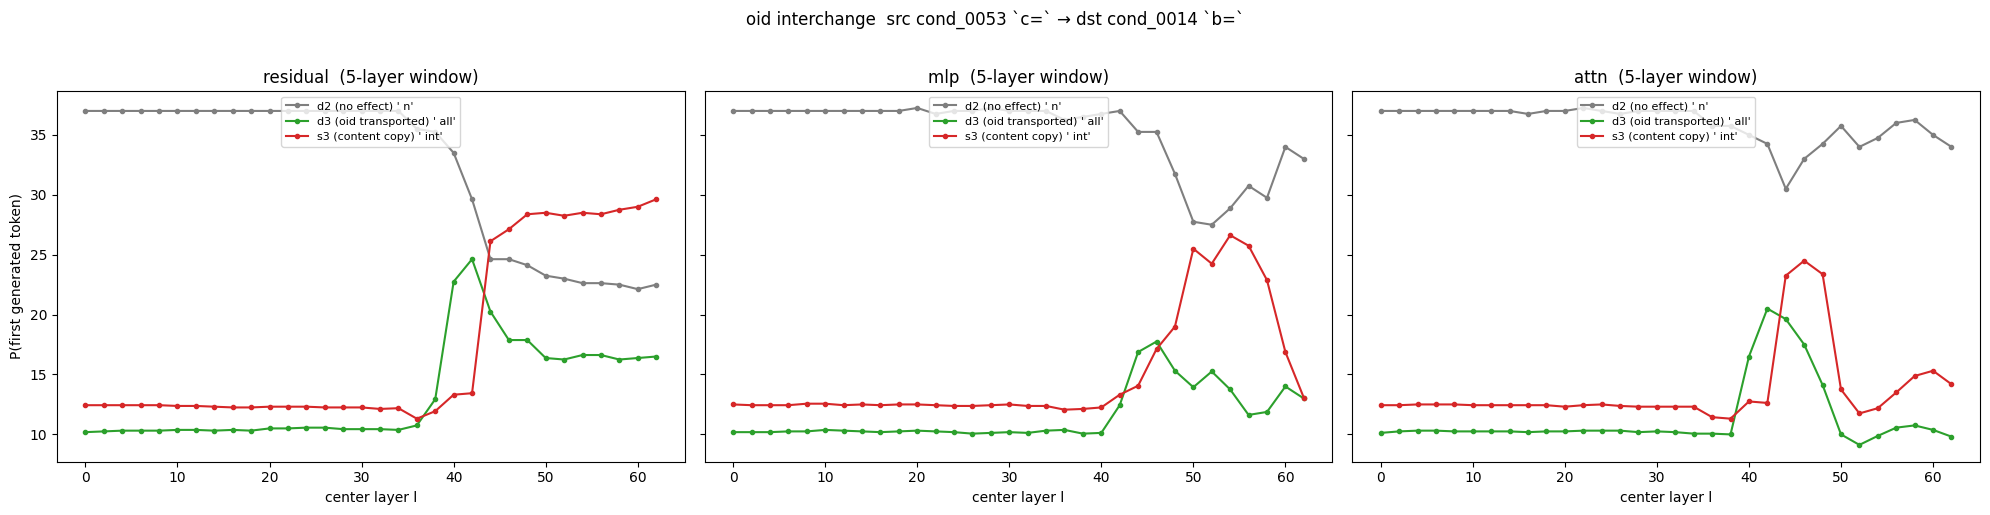

residual — argmax first token by center layer:
  l= 0: ' n'           [d2]
  l= 2: ' n'           [d2]
  l= 4: ' n'           [d2]
  l= 6: ' n'           [d2]
  l= 8: ' n'           [d2]
  l=10: ' n'           [d2]
  l=12: ' n'           [d2]
  l=14: ' n'           [d2]
  l=16: ' n'           [d2]
  l=18: ' n'           [d2]
  l=20: ' n'           [d2]
  l=22: ' n'           [d2]
  l=24: ' n'           [d2]
  l=26: ' n'           [d2]
  l=28: ' n'           [d2]
  l=30: ' n'           [d2]
  l=32: ' n'           [d2]
  l=34: ' n'           [d2]
  l=36: ' n'           [d2]
  l=38: ' n'           [d2]
  l=40: ' n'           [d2]
  l=42: ' n'           [d2]
  l=44: ' int'         [s3]
  l=46: ' int'         [s3]
  l=48: ' int'         [s3]
  l=50: ' int'         [s3]
  l=52: ' int'         [s3]
  l=54: ' int'         [s3]
  l=56: ' int'         [s3]
  l=58: ' int'         [s3]
  l=60: ' int'         [s3]
  l=62: ' int'         [s3]


In [38]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 5), sharey=True)
for ax, (mod_name, _) in zip(axes, MODULES):
    rows = sweeps[mod_name]
    cs = [r["center"] for r in rows]
    ax.plot(cs, [r["p_d2"] for r in rows], "-o", ms=3, label=f"d2 (no effect) {dec(t_d2)!r}", color="tab:gray")
    ax.plot(cs, [r["p_d3"] for r in rows], "-o", ms=3, label=f"d3 (oid transported) {dec(t_d3)!r}", color="tab:green")
    ax.plot(cs, [r["p_s3"] for r in rows], "-o", ms=3, label=f"s3 (content copy) {dec(t_s3)!r}", color="tab:red")
    ax.set_title(f"{mod_name}  (5-layer window)")
    ax.set_xlabel("center layer l")
    ax.legend(fontsize=8, loc="upper center")
axes[0].set_ylabel("P(first generated token)")
fig.suptitle(f"oid interchange  src {SRC_SAMPLE} `c=` → dst {DST_SAMPLE} `b=`", y=1.02)
plt.tight_layout()
plt.show()

# argmax token per center (residual), to eyeball the transition
print("residual — argmax first token by center layer:")
for r in sweeps["residual"]:
    which = {t_d2: "d2", t_d3: "d3", t_s3: "s3"}.get(r["argmax"], "·")
    print(f"  l={r['center']:2d}: {dec(r['argmax'])!r:14s} [{which}]")

## 4. (follow-up) consecutive generation

Once the first-token picture is clear, extend to held-patch generation (patch the
window at the `b = ` position on the prefill pass, then decode). Left as a stub —
decide the readout after inspecting §3.

In [7]:
# follow-up: consecutive generation with the patch held (see src.functional.generate_with_patch)

## 3b. Content-averaged order-id vector

Instead of a single (entangled) source prompt, build a **content-averaged** order-id
vector: for `oid ∈ {0,1,2}`, average the module latent over the first `K` tokens of
the `oid`-th instruction span across many prompts. The hope is that the predicate
*content* cancels and the shared "being the n-th instruction" factor survives.
Caveat: the mean keeps the instruction scaffolding too (numbering, " n is", position) —
the **difference** `μ_target − μ_current` isolates the order delta, so we test both
`replace(μ_target)` and `add(μ_target − μ_current)`. Inject site is an hparam:
the assignment site `b =`, or the dest's own current-instruction span.

In [ ]:
import torch.nn.functional as F
from tqdm.auto import tqdm

FORMATS = {"residual": mt.layer_name_format, "attn": mt.attn_module_name_format}


def instr_span(lab, oid):
    sp = lab.labels[oid].prompt_token_range if oid < len(lab.labels) else None
    return tuple(sp) if sp else None


@torch.no_grad()
def accumulate_oid_latents(oids=(0, 1, 2), k=5, limit=200, modularity="monolithic"):
    """Mean module latent over the first k tokens of the oid-th instruction span,
    pooled across prompts. Returns mu[(module, oid)] = (n_layer, n_embd), counts, n_used."""
    samples = list_monolithic_samples()[:limit]
    sums = {(m, o, l): torch.zeros(mt.n_embd) for m in FORMATS for o in oids for l in range(mt.n_layer)}
    counts = {o: 0 for o in oids}
    used = 0
    for sname in tqdm(samples):
        lab, _ = load_labeled(sname, modularity)
        spans = {o: instr_span(lab, o) for o in oids}
        pos = {o: list(range(sp[0], min(sp[0] + k, sp[1]))) for o, sp in spans.items() if sp}
        if len(pos) < len(oids):                      # need all target oids present
            continue
        allpos = sorted({p for ps in pos.values() for p in ps})
        ridx = {p: i for i, p in enumerate(allpos)}
        inp = prepare_input(prompts=[lab.full_prompt], tokenizer=mt, add_special_tokens=False)
        cap = {}
        with mt.trace({"input_ids": inp["input_ids"], "attention_mask": inp["attention_mask"]},
                      scan=False, validate=False):
            for l in range(mt.n_layer):               # strict execution order: per layer, attn precedes residual
                amod = get_module_nnsight(mt, mt.attn_module_name_format.format(l))
                cap[("attn", l)] = amod.output[0][0, allpos, :].save()
                rmod = get_module_nnsight(mt, mt.layer_name_format.format(l))
                cap[("residual", l)] = rmod.output[0, allpos, :].save()
        for m in FORMATS:
            for l in range(mt.n_layer):
                c = cap[(m, l)].detach().float().cpu()
                for o, ps in pos.items():
                    sums[(m, o, l)] += c[[ridx[p] for p in ps]].sum(0)
        for o, ps in pos.items():
            counts[o] += len(ps)
        used += 1
    mu = {(m, o): torch.stack([sums[(m, o, l)] / max(counts[o], 1) for l in range(mt.n_layer)])
          for m in FORMATS for o in oids}
    return mu, counts, used


def oid_latents_path(oids, k, limit, modularity):
    tag = f"oids-{''.join(map(str, oids))}_k{k}_lim{limit}_{modularity}"
    d = os.path.join(env_utils.DEFAULT_RESULTS_DIR, "oid_latents", MODEL_SHORT)
    os.makedirs(d, exist_ok=True)
    return os.path.join(d, tag + ".pt")


def get_oid_latents(oids=(0, 1, 2), k=5, limit=200, modularity="monolithic", overwrite=False):
    """Cached accumulate_oid_latents (saved under results/oid_latents/<model>/)."""
    p = oid_latents_path(oids, k, limit, modularity)
    if os.path.exists(p) and not overwrite:
        blob = torch.load(p, weights_only=False)
        print(f"loaded cached oid latents \u2190 {p}  (n_used={blob['n_used']})")
        return blob["mu"], blob["counts"], blob["n_used"]
    mu_, counts_, used_ = accumulate_oid_latents(oids, k, limit, modularity)
    torch.save({"mu": mu_, "counts": counts_, "n_used": used_,
                "config": dict(oids=list(oids), k=k, limit=limit,
                               modularity=modularity, model=MODEL_NAME)}, p)
    print(f"saved oid latents \u2192 {p}  (n_used={used_})")
    return mu_, counts_, used_


OIDS = (0, 1, 2)
K = 5
LIMIT = 200
OVERWRITE = False
mu, oid_counts, n_used = get_oid_latents(OIDS, K, LIMIT, overwrite=OVERWRITE)
print(f"oid latents from {n_used} prompts; tokens/oid={oid_counts}")

# sanity: how separable are the oid means? (cos should be high but < 1; delta non-trivial)
for m in FORMATS:
    print(f"[{m}]")
    for a, b in [(0, 1), (1, 2), (0, 2)]:
        cs = F.cosine_similarity(mu[(m, a)], mu[(m, b)], dim=-1)        # (n_layer,)
        print(f"   cos(μ{a}, μ{b}): mean={cs.mean():.3f}  min={cs.min():.3f}  "
              f"|μ{b}-μ{a}| mean-norm={ (mu[(m,b)]-mu[(m,a)]).norm(dim=-1).mean():.2f}")

  0%|          | 0/200 [00:00<?, ?it/s]

In [ ]:
@torch.no_grad()
def patched_logits_oid(prompt, name_format, layer_vec, positions, strategy="replace", pos_read=-1):
    """Apply `layer_vec[l]` (replace|add) at every position in `positions`, for each
    layer; return next-token logits at `pos_read` (vocab,) CPU."""
    inp = prepare_input(prompts=[prompt], tokenizer=mt, add_special_tokens=False)
    with mt.trace({"input_ids": inp["input_ids"], "attention_mask": inp["attention_mask"]},
                  scan=False, validate=False):
        for l in sorted(layer_vec):                    # ascending = execution order
            name = name_format.format(l)
            mod = get_module_nnsight(mt, name)
            state = mod.output[0] if "attn" in name else mod.output
            v = layer_vec[l].to(device=state.device, dtype=state.dtype)
            for p in positions:
                if strategy == "replace":
                    state[:, p, :] = v
                else:
                    state[:, p, :] = state[:, p, :] + v
        logits = mt.output.logits[:, pos_read, :].save()
    return logits[0].detach().float().cpu()


def run_oid_sweep(module, target_oid, cur_oid, dst_prefill, dst_lab, refs, centers,
                  inject_site="assignment", strategy="replace", k=K, half=WINDOW_HALF):
    fmt = FORMATS[module]
    mu_t, mu_c = mu[(module, target_oid)], mu[(module, cur_oid)]
    if inject_site == "assignment":
        positions = [-1]                               # the `b =` token that writes the RHS
    else:                                              # overwrite dest's own current-instruction span
        sp = instr_span(dst_lab, cur_oid)
        positions = list(range(sp[0], min(sp[0] + k, sp[1])))
    rows = []
    for c in centers:
        win = [l for l in range(c - half, c + half + 1) if 0 <= l < mt.n_layer]
        layer_vec = {l: (mu_t[l] if strategy == "replace" else mu_t[l] - mu_c[l]) for l in win}
        lg = patched_logits_oid(dst_prefill, fmt, layer_vec, positions, strategy)
        rows.append(dict(center=c, argmax=int(lg.argmax()),
                         p_d2=float(lg[refs["d2"]]), p_d3=float(lg[refs["d3"]]), p_s3=float(lg[refs["s3"]])))
    return rows


### ---- oid-patch config ----
TARGET_OID  = 2                 # push the order id to this
CUR_OID     = 1                 # `b =` implements oid 1
INJECT_SITE = "assignment"      # "assignment" | "instruction_span"
### --------------------------
oid_sweeps = {}
for module in ("residual", "attn"):
    for strat in ("replace", "add"):
        rich_print(f"[cyan]oid sweep · {module} · {strat} · inject={INJECT_SITE} …[/]")
        oid_sweeps[(module, strat)] = run_oid_sweep(
            module, TARGET_OID, CUR_OID, dst_prefill_b, dst_lab, refs, centers, INJECT_SITE, strat)

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True)
combos = [(m, s) for m in ("residual", "attn") for s in ("replace", "add")]
for ax, (module, strat) in zip(axes.flat, combos):
    rows = oid_sweeps[(module, strat)]
    cs = [r["center"] for r in rows]
    ax.plot(cs, [r["p_d2"] for r in rows], "-o", ms=3, label=f"d2 (no effect) {dec(t_d2)!r}", color="tab:gray")
    ax.plot(cs, [r["p_d3"] for r in rows], "-o", ms=3, label=f"d3 (oid→{TARGET_OID}) {dec(t_d3)!r}", color="tab:green")
    ax.plot(cs, [r["p_s3"] for r in rows], "-o", ms=3, label=f"s3 (null) {dec(t_s3)!r}", color="tab:red")
    ax.set_title(f"{module} · {strat}")
    ax.legend(fontsize=8, loc="upper center")
for ax in axes[-1]:
    ax.set_xlabel("center layer l")
for ax in axes[:, 0]:
    ax.set_ylabel("logit(first token)")
fig.suptitle(f"oid vector  (μ_{CUR_OID}→μ_{TARGET_OID}, K={K}, n={n_used})  inject={INJECT_SITE}  "
             f"dst {DST_SAMPLE} `b=`", y=1.01)
plt.tight_layout()
plt.show()